<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 5: Constraint Satisfaction — N-Queens, Map Colouring and Sudoku</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.2 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Solve CSPs (N-Queens, map colouring of Australia and Sudoku) using backtracking search enhanced with MRV, forward checking and AC-3.</div>

## 📘 Theory

A CSP is $\langle X,D,C\rangle$. **Backtracking** assigns one variable at a time and undoes an assignment when a variable has no legal value.
Heuristics: **MRV** (choose the variable with fewest legal values), **LCV**, **forward checking**. **AC-3** enforces arc consistency by deleting unsupported values.

## 🧭 Algorithm

1. If the assignment is complete, return it.
2. Select an unassigned variable (MRV).
3. For each value consistent with the assignment: assign it, run forward checking/AC-3, recurse.
4. If recursion fails, undo the assignment and try the next value; if none remain, backtrack.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
def nqueens(n):
    sol, trace, calls = [], [], [0]
    def ok(col, row):
        return all(r != row and abs(r - row) != col - c for c, r in enumerate(sol))
    def bt(col):
        calls[0] += 1
        if col == n: return True
        for row in range(n):
            if ok(col, row):
                sol.append(row); trace.append(sol[:])
                if bt(col + 1): return True
                sol.pop(); trace.append(sol[:])
        return False
    bt(0); return sol, trace, calls[0]
sol, trace, calls = nqueens(8)
print("8-Queens solution (row of queen in each column):", sol, "| recursive calls:", calls, "| board states:", len(trace))
for n in (4, 6, 8, 10, 12):
    s, t, c = nqueens(n); print(f"  n={n:>2}: first solution {s}  calls={c}")

8-Queens solution (row of queen in each column): [0, 4, 7, 5, 2, 6, 1, 3] | recursive calls: 114 | board states: 218
  n= 4: first solution [1, 3, 0, 2]  calls=9
  n= 6: first solution [1, 3, 5, 0, 2, 4]  calls=32
  n= 8: first solution [0, 4, 7, 5, 2, 6, 1, 3]  calls=114
  n=10: first solution [0, 2, 5, 7, 9, 4, 8, 1, 3, 6]  calls=103
  n=12: first solution [0, 2, 4, 7, 9, 11, 5, 10, 1, 6, 8, 3]  calls=262


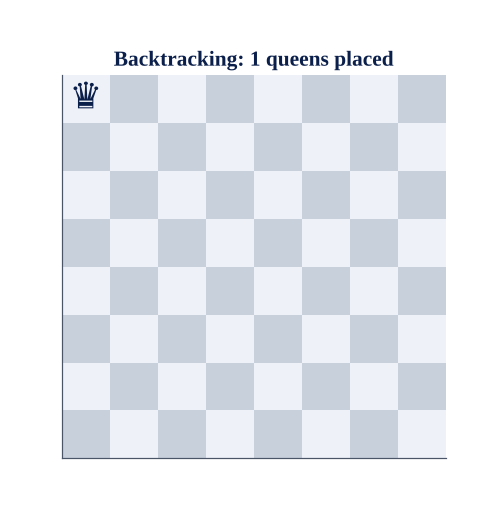

In [3]:
fig, ax = plt.subplots(figsize=(4.5, 4.8))
keep = trace[::max(1, len(trace)//40)] + [trace[-1]] * 4
def drawq(k):
    s = keep[k]; ax.clear(); n = 8
    ax.imshow([[(i + j) % 2 for j in range(n)] for i in range(n)], cmap=matplotlib.colors.ListedColormap([MIST, "#C8D0DC"]))
    for c, r in enumerate(s): ax.text(c, r, "♛", ha="center", va="center", fontsize=24, fontfamily="DejaVu Sans", color=LEAF if len(s) == 8 else NAVY)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"Backtracking: {len(s)} queens placed")
gif = save_gif(animation.FuncAnimation(fig, drawq, frames=len(keep)), "exp05_nqueens_backtracking.gif", fps=4)
display(Image(filename=gif))

### Map colouring of Australia — backtracking + MRV + forward checking

In [4]:
NB = {"WA":["NT","SA"],"NT":["WA","SA","Q"],"SA":["WA","NT","Q","NSW","V"],"Q":["NT","SA","NSW"],"NSW":["Q","SA","V"],"V":["SA","NSW"],"T":[]}
COLS = ["red", "green", "blue"]
def colour(assign, domains, log):
    if len(assign) == len(NB): return assign
    var = min((v for v in NB if v not in assign), key=lambda v: (len(domains[v]), -len(NB[v])))   # MRV + degree
    for val in domains[var]:
        new_d = {k: list(d) for k, d in domains.items()}; new_d[var] = [val]; ok = True
        for nb in NB[var]:
            if nb not in assign and val in new_d[nb]:
                new_d[nb].remove(val); ok &= bool(new_d[nb])   # forward checking
        if ok:
            log.append(f"{var} = {val}"); r = colour({**assign, var: val}, new_d, log)
            if r: return r
            log.append(f"backtrack on {var}")
    return None
log = []; res = colour({}, {v: COLS[:] for v in NB}, log)
print("Assignment order:", " → ".join(log)); print("Solution:", res)

Assignment order: SA = red → NT = green → Q = blue → NSW = green → WA = blue → V = blue → T = red
Solution: {'SA': 'red', 'NT': 'green', 'Q': 'blue', 'NSW': 'green', 'WA': 'blue', 'V': 'blue', 'T': 'red'}


In [5]:
import networkx as nx
pos = {"WA":(0,1.2),"NT":(1.3,2),"SA":(1.6,0.9),"Q":(2.8,2),"NSW":(3,0.8),"V":(2.5,-0.2),"T":(2.7,-1.2)}
Gm = nx.Graph([(a, b) for a in NB for b in NB[a]]); Gm.add_node("T")
pal = {"red": CRIMSON, "green": LEAF, "blue": NAVY2}
plt.figure(figsize=(5.5, 4.2))
nx.draw(Gm, pos, with_labels=True, node_color=[pal[res[n]] for n in Gm.nodes], node_size=1700, font_color="white",
        font_weight="bold", font_family="serif", edge_color=GOLD, width=2.5)
plt.title("Australia map colouring — constraint graph"); plt.savefig(f"{FIG}/exp05_map_colouring.png", dpi=130, bbox_inches="tight"); plt.show()

### Sudoku with AC-3 + backtracking

In [6]:
PUZ = "530070000600195000098000060800060003400803001700020006060000280000419005000080079"
cells = [(r, c) for r in range(9) for c in range(9)]
peers = {x: {y for y in cells if y != x and (y[0] == x[0] or y[1] == x[1] or (y[0]//3, y[1]//3) == (x[0]//3, x[1]//3))} for x in cells}
def ac3(D):
    q = [(x, y) for x in cells for y in peers[x]]
    while q:
        x, y = q.pop()
        if len(D[y]) == 1 and D[y][0] in D[x]:
            D[x] = [v for v in D[x] if v != D[y][0]]
            if not D[x]: return False
            q.extend((z, x) for z in peers[x] if z != y)
    return True
def solve(D, stats):
    if not ac3(D): return None
    if all(len(d) == 1 for d in D.values()): return D
    x = min((c for c in cells if len(D[c]) > 1), key=lambda c: len(D[c]))
    for v in D[x]:
        stats[0] += 1; E = {k: list(d) for k, d in D.items()}; E[x] = [v]
        r = solve(E, stats)
        if r: return r
    return None
D0 = {(r, c): [int(PUZ[r*9+c])] if PUZ[r*9+c] != "0" else list(range(1, 10)) for r, c in cells}
D1 = {k: list(v) for k, v in D0.items()}; ac3(D1)
print("Unknown cells before AC-3:", sum(len(v) > 1 for v in D0.values()), "| after AC-3 alone:", sum(len(v) > 1 for v in D1.values()))
stats = [0]; S = solve(D0, stats); print("Guesses needed by backtracking:", stats[0])
fig, ax = plt.subplots(figsize=(4.6, 4.6)); ax.set_xlim(0, 9); ax.set_ylim(0, 9); ax.axis("off")
for (r, c), v in S.items():
    given = PUZ[r*9+c] != "0"
    ax.add_patch(plt.Rectangle((c, 8 - r), 1, 1, color=GOLDL if given else "white", ec="#C8D0DC"))
    ax.text(c + .5, 8.5 - r, v[0], ha="center", va="center", fontsize=15, color=NAVY if given else TEAL, weight="bold" if given else "normal")
for t in range(0, 10, 3): ax.plot([t, t], [0, 9], color=NAVY, lw=2.5); ax.plot([0, 9], [t, t], color=NAVY, lw=2.5)
ax.set_title("Sudoku solved (givens shaded)")
HARD = "800000000003600000070090200050007000000045700000100030001000068008500010090000400"   # 'world's hardest' (Inkala)
Dh = {(r, c): [int(HARD[r*9+c])] if HARD[r*9+c] != "0" else list(range(1, 10)) for r, c in cells}
Dh1 = {k: list(v) for k, v in Dh.items()}; ac3(Dh1)
st2 = [0]; Sh = solve(Dh, st2)
print(f"Hard puzzle: unknown after AC-3 = {sum(len(v) > 1 for v in Dh1.values())}, backtracking guesses = {st2[0]}")
print("Hard puzzle first row solved:", [Sh[(0, c)][0] for c in range(9)]); plt.savefig(f"{FIG}/exp05_sudoku.png", dpi=130, bbox_inches="tight"); plt.show()

Unknown cells before AC-3: 51 | after AC-3 alone: 0
Guesses needed by backtracking: 0


Hard puzzle: unknown after AC-3 = 60, backtracking guesses = 1850
Hard puzzle first row solved: [8, 1, 2, 7, 5, 3, 6, 4, 9]


## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>Backtracking finds the first 8-queens solution in about a hundred recursive calls; MRV with forward checking colours Australia without any backtracking; AC-3 alone solves an easy Sudoku, while the 'hardest' Sudoku additionally needs backtracking guesses guided by MRV.</div>

## 🎤 Viva Questions

1. Define a CSP with its three components for map colouring.
2. What is the MRV heuristic and why is it called fail-first?
3. Differentiate forward checking from arc consistency.
4. What is the complexity of AC-3?
5. Why is Tasmania irrelevant in the Australia map-colouring problem?